**Note:**
Changing from GPU to CPU

In [ ]:
!pip install -q easyocr transformers sentencepiece accelerate

In [ ]:
import os
import re
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

import torch
import easyocr

print("PyTorch version:", torch.__version__)

DEVICE = "cpu"

print("Device:", DEVICE)
print("Project Environment is ready!")

PyTorch version: 2.14.1+cpu
Device: cpu
Project Environment is ready!


In [ ]:
DEVICE = "cpu"

In [ ]:
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Done!! Project folders created")

Done!! Project folders created


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving basic-bar-chart-example-1200x655.webp to basic-bar-chart-example-1200x655.webp


In [ ]:
uploaded_file_name = list(uploaded.keys())[0]
print("Uploaded file name:", uploaded_file_name)

Uploaded file name: basic-bar-chart-example-1200x655.webp


Image size: (860, 469)


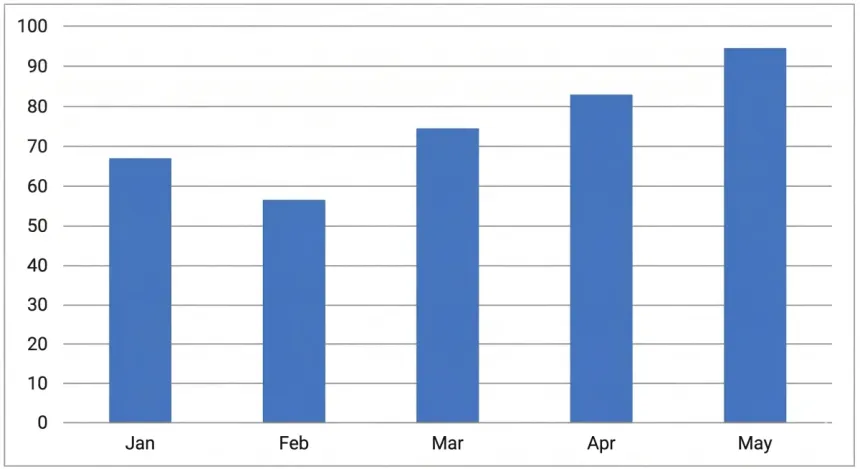

In [ ]:
image = Image.open(uploaded_file_name).convert("RGB")

print("Image size:", image.size)
display(image)

In [ ]:
# Initializing EasyOCR
ocr_reader = easyocr.Reader(
    ["en"],
    gpu=False
)

print("EasyOCR model loadead/initialized!")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR model loadead/initialized!


/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/dynamic/modules/rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/quantized/Quantizer.cpp:111.)
  w_ih = torch.quantize_per_tensor(


In [ ]:
def extract_ocr_with_positions(pil_image):
  image_array = np.array(pil_image)

  detections = ocr_reader.readtext(
      image_array,
      detail = 1
  )

  results = []

  for bbox, text, confidence in detections:
    if confidence >= 0.25:

      x_coordinates = [
          point[0] for point in bbox
      ]
      y_coordinates = [
          point[1] for point in bbox
      ]

      result = {
          "text": text,
          "confidence": round(
              float(confidence), 3
          ),
          "x": round(float(min(x_coordinates)),1),
          "y": round(float(min(y_coordinates)), 1),

      }
      results.append(result)

  return results

In [ ]:
# Extracting Text,Confidence score
# X-coordinate, Y-coordinate
# Helps with chart layout

ocr_results = extract_ocr_with_positions(image)

print("OCR results\n")

for item in ocr_results:
  print(
      f"Text: {item['text']:<20} |"
      f"Confidence: {item['confidence']:<6} |"
      f"X: ({item['x']}, {item['y']})"
  )

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


OCR results

Text: 100                  |Confidence: 1.0    |X: (15.0, 15.0)
Text: 90                   |Confidence: 1.0    |X: (24.0, 54.0)
Text: 80                   |Confidence: 1.0    |X: (25.0, 97.0)
Text: 70                   |Confidence: 1.0    |X: (25.0, 135.0)
Text: 60                   |Confidence: 1.0    |X: (25.0, 175.0)
Text: 50                   |Confidence: 1.0    |X: (27.0, 215.0)
Text: 40                   |Confidence: 1.0    |X: (25.0, 255.0)
Text: 30                   |Confidence: 1.0    |X: (25.0, 295.0)
Text: 20                   |Confidence: 1.0    |X: (25.0, 333.0)
Text: 10                   |Confidence: 1.0    |X: (25.0, 373.0)
Text: Jan                  |Confidence: 1.0    |X: (123.0, 433.0)
Text: Feb                  |Confidence: 1.0    |X: (277.0, 433.0)
Text: Mar                  |Confidence: 1.0    |X: (431.0, 433.0)
Text: Apr                  |Confidence: 1.0    |X: (584.0, 432.0)
Text: May                  |Confidence: 1.0    |X: (736.0, 432.0)


In [18]:
# Converting the OCR results into clean text
def clean_ocr_text(ocr_results):

  texts = []

  for item in ocr_results:
    text = item["text"].strip()

    if text:
      texts.append(text)

  return texts

  ocr_text_list = clean_ocr_text(
      ocr_results
  )

  print("EXTRACTED TEXT\n")

  for text in ocr_text_list:
    print(text)

In [ ]:
# Call the function to properly define the list globally
ocr_text_list = clean_ocr_text(ocr_results)

# Function to Identify numbers and labels
def extract_numbers_and_labels(text_list):

  numbers = []
  labels = []

  for text in text_list:

    cleaned = text.replace(",","").strip()

    number_match = re.fullmatch(
        r"-?\d+(?:\.\d+)?%?" ,
        cleaned
    )

    if number_match:

      numeric_text = cleaned.replace("%","")

      try:
        numbers.append(
            float(numeric_text)
        )

      except ValueError:
         pass
    else:
      labels.append(text)

  return labels, numbers

labels, numbers = extract_numbers_and_labels(
    ocr_text_list
)

print("Possible Labels:")
print(labels)

print("\nPossible Numbers:")
print(numbers)

Possible Labels:
['Jan', 'Feb', 'Mar', 'Apr', 'May']

Possible Numbers:
[100.0, 90.0, 80.0, 70.0, 60.0, 50.0, 40.0, 30.0, 20.0, 10.0]


In [19]:
#Correction step

chart_data = {}

print("Create structured chart data.")
print("Enter the categories and the values")
print("Type 'done' when finished\n")

while True:
  category = input("Enter Category Name:(or done): ")

  if category.lower() == "done":
    break

  value = input(f"Enter value for {category}: ")

  # Corrected indentation: this try-except block must be inside the while loop
  try:
    chart_data[category] = float(value)
  except ValueError:
    print("Invalid number. Please try again")

print("\nFinal Structured Data:")
print(chart_data)

Create structured chart data.
Enter the categories and the values
Type 'done' when finished

Enter Category Name:(or done): 'Jan'
Enter value for 'Jan': 60.0
Enter Category Name:(or done): 'Feb'
Enter value for 'Feb': 50.0
Enter Category Name:(or done): 'Mar'
Enter value for 'Mar': 70.0
Enter Category Name:(or done): 'Apr'
Enter value for 'Apr': 80.0
Enter Category Name:(or done): 'May'
Enter value for 'May': 90.0
Enter Category Name:(or done): done

Final Structured Data:
{"'Jan'": 60.0, "'Feb'": 50.0, "'Mar'": 70.0, "'Apr'": 80.0, "'May'": 90.0}


In [20]:
def analyze_chart_data(data):

    if not data:
        return None

    categories = list(data.keys())
    values = list(data.values())

    max_value = max(values)
    min_value = min(values)

    max_index = values.index(max_value)
    min_index = values.index(min_value)

    analysis = {
        "total_categories": len(categories),

        "highest_category":
            categories[max_index],

        "highest_value":
            max_value,

        "lowest_category":
            categories[min_index],

        "lowest_value":
            min_value,

        "first_category":
            categories[0],

        "first_value":
            values[0],

        "last_category":
            categories[-1],

        "last_value":
            values[-1]
    }

    if len(values) >= 2:

        analysis["overall_change"] = (
            values[-1] - values[0]
        )

    return analysis

In [21]:
analysis = analyze_chart_data(chart_data)

if analysis is None:
  print("No analysis results found. Please fix the indentation of the try-except block in cell BvYxKPTjowWt, re-run it, and enter your data again.")
else:
  print("Analysis Results:")
  for key, value in analysis.items():
    print(f"{key}: {value}")

Analysis Results:
total_categories: 5
highest_category: 'May'
highest_value: 90.0
lowest_category: 'Feb'
lowest_value: 50.0
first_category: 'Jan'
first_value: 60.0
last_category: 'May'
last_value: 90.0
overall_change: 30.0


In [22]:
# Creating evidence for the language model
# Reminder: All LM should receive clean,factual information

def create_evidence(data, analysis):

  if not data or not analysis:
    raise ValueError("Chart data or analysis is empty.")

  evidence = "Chart Data:\n"

  for category, value in data.items():

    evidence += f"{category}: {value}\n"

  evidence += "\nAnalysis Results:\n"

  evidence += (
      f"Highest value:"
      f"{analysis['highest_category']}: "
      f"with {analysis['highest_value']}\n"
  )

  evidence += (
      f"Lowest value:"
      f"{analysis['lowest_category']}: "
      f"with {analysis['lowest_value']}\n"
  )

  evidence += (
      f"Overall change:"
      f"category{analysis['overall_change']}\n")

  change = analysis.get("overall_change", "Not available")

  evidence += (f"Overall change: {change}\n")

  return evidence

print("Generating chart evidence...")

evidence = create_evidence(chart_data, analysis)

print("\nGENERATED SUCEESFULLY!\n")
print(evidence)

Generating chart evidence...

GENERATED SUCEESFULLY!

Chart Data:
'Jan': 60.0
'Feb': 50.0
'Mar': 70.0
'Apr': 80.0
'May': 90.0

Analysis Results:
Highest value:'May': with 90.0
Lowest value:'Feb': with 50.0
Overall change:category30.0
Overall change: 30.0



In [23]:
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

MODEL_ID = "google/flan-t5-small"

print("Loading FLAN-T5-small...")
print("This may take a few minutes on the first run.")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_ID
)

model.to("cpu")

model.eval()

print("FLAN-T5-small loaded successfully!")

Loading FLAN-T5-small...
This may take a few minutes on the first run.


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5-small loaded successfully!


In [24]:
model.to("cpu")

T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=384, bias=False)
              (k): Linear(in_features=512, out_features=384, bias=False)
              (v): Linear(in_features=512, out_features=384, bias=False)
              (o): Linear(in_features=384, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 6)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=512, out_features=1024, bias=False)
              (wi_1): Linear(in_features=512, out_features=1024, bias=False)
              (wo): 

In [25]:
# Generating the natural language summary
def generate_nlp_summary(evidence_text):

  prompt = (
      "Summarize this chart data in 2 short sentences."
      "Mention the highest value and the lowest value."
      "Use only the data provided.\n\n"
      f"{evidence_text}\n\n"
      "Write the summary:"
  )

  inputs = tokenizer(
      prompt,
      return_tensors = "pt",
      truncation = True,
      max_length = 512
  )

  inputs = {key: value.to("cpu")
      for key, value in inputs.items()}

  with torch.no_grad():

    outputs = model.generate(
        **inputs,
        max_new_tokens = 100,
        min_new_tokens = 10,
        num_beams = 4,
        do_sample = False,
        early_stopping = True
    )

  summary = tokenizer.decode(
      outputs[0],
      skip_special_tokens = True
  ).strip()

  return summary

In [26]:
print("Evidence being sent to the model:\n")
print(evidence)

final_summary = generate_nlp_summary(evidence)

print("\nFinal NLP Summary:")
print(final_summary)

Evidence being sent to the model:

Chart Data:
'Jan': 60.0
'Feb': 50.0
'Mar': 70.0
'Apr': 80.0
'May': 90.0

Analysis Results:
Highest value:'May': with 90.0
Lowest value:'Feb': with 50.0
Overall change:category30.0
Overall change: 30.0


Final NLP Summary:
May is the highest value and the lowest value.


In [27]:
# Added Fallback Summary
def create_template_summary(analysis):

  change = analysis["overall_change"]

  if change > 0:
    trend = "an overall increase"
  elif change < 0:
    trend = "an overall decrease"
  else:
    trend = "no overall change"

  summary = (
      f"The chart shows {trend} from "
      f"{analysis['first_category']} "
      f"{analysis['first_value']} to "
      f"{analysis['last_category']} "
      f"{analysis['last_value']}. "
      f"{analysis['highest_category']} has the"
      f"highest value of "
      f"{analysis['highest_value']},while"
      f"{analysis['lowest_category']} has the "
      f"lowest value of "
      f"{analysis['lowest_value']}."
      )

  return summary

In [28]:
# More Natural Summary
template_summary = create_template_summary(analysis)

print("Template Summary:")
print(template_summary)

Template Summary:
The chart shows an overall increase from 'Jan' 60.0 to 'May' 90.0. 'May' has thehighest value of 90.0,while'Feb' has the lowest value of 50.0.


In [29]:
result = {
    "image_name": uploaded_file_name,
    "ocr_results": ocr_results,
    "structured_chart_data": chart_data,
    "analysis_results": analysis,
    "evidence": evidence,
    "nlp_summary": final_summary,
    "template_summary": template_summary
}

output_path = "results/char_result.json"

with open(
    output_path,
    "w"
 ) as file:

  json.dump(
      result,
      file,
      indent=4)

print(f"Results saved to {output_path}")

Results saved to results/char_result.json


**Combining Process the stages and Testing**

In [30]:
# Combining the Process Stages
def process_image(image_path):

  print("Loading the image...")

  pill_image = Image.open(image_path).convert("RGB")

  print("Image loaded successfully!")

  print("Extracting OCR results...")

  ocr_results = extract_ocr_with_positions(pill_image)
  ocr_text_list = clean_ocr_text(ocr_results)
  labels, numbers = extract_numbers_and_labels(ocr_text_list)

  print("\nDetected labels:")
  print(labels)

  print("\nDetected numbers:")
  print(numbers)

  return {
      "image_name": pill_image,
      "ocr_results": ocr_results,
      "labels": labels,
      "numbers": numbers
  }

In [31]:
extraction_result = process_image(uploaded_file_name)

Loading the image...
Image loaded successfully!
Extracting OCR results...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Detected labels:
['Jan', 'Feb', 'Mar', 'Apr', 'May']

Detected numbers:
[100.0, 90.0, 80.0, 70.0, 60.0, 50.0, 40.0, 30.0, 20.0, 10.0]


**Testing Random Images**

In [54]:
# Testing Random Chart Images
from google.colab import files

uploaded = files. upload()
upload_filename = list(uploaded.keys())[0]

Saving horizontal-bar-chart-example-department-ranking-1200x655.webp to horizontal-bar-chart-example-department-ranking-1200x655 (1).webp


In [55]:
extraction_result = process_image(upload_filename)


Loading the image...
Image loaded successfully!
Extracting OCR results...

Detected labels:
['Department Performance Ranking', 'Sales', 'Marketing', 'Operations', 'Finance', 'HR', 'Legal', 'Value']

Detected numbers:
[100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0, 500.0]


In [56]:
#Organizing the data and generating final summary
chart_data = {
    "Sales:":500.0,
    "Marketing:":450.0,
    "Operations:":400.0,
    "Finance:":350.0,
    "HR:":300.0,
    "IT": 250.0,
    "Legal:":200.0
}

analysis = analyze_chart_data(chart_data)

evidence = create_evidence(chart_data, analysis)

final_summary = generate_nlp_summary(evidence)

template_summary = create_template_summary(analysis)

print("Final Summary:")
print(final_summary)

print("\nTemplate Summary:")
print(template_summary)

Final Summary:
The highest value and the lowest value are Sales and Marketing.

Template Summary:
The chart shows an overall decrease from Sales: 500.0 to Legal: 200.0. Sales: has thehighest value of 500.0,whileLegal: has the lowest value of 200.0.


In [59]:
result = {
    "image_name": uploaded_file_name,
    "ocr_results": ocr_results,
    "structured_chart_data": chart_data,
    "analysis_results": analysis,
    "evidence": evidence,
    "nlp_summary": final_summary,
    "template_summary": template_summary
}

output_path = "results/char_result.json"

with open(
    output_path,
    "w"
 ) as file:

  json.dump(
      result,
      file,
      indent=4)

print(f"Results saved to {output_path}")

Results saved to results/char_result.json


In [44]:
#Upload Image
from google.colab import files

uploaded = files.upload()
uploaded_filename = list(uploaded.keys())[0]

Saving InfoGraphic1.png to InfoGraphic1 (2).png


In [45]:
extraction_result = process_image(uploaded_filename)

Loading the image...
Image loaded successfully!
Extracting OCR results...

Detected labels:
['ILLUSTRATIVE', 'ENERGY MIX', 'Synthetic example infographic for OCR and summarisation testing', 'SOLAR', 'WIND', 'HYDRO', 'Largest share in this example', 'Second-largest share', 'Smallest share', 'TOTAL: 100%', 'DATA: SYNTHETIC', 'FOR DEMONSTRATION ONLY']

Detected numbers:
[45.0, 35.0, 20.0]


In [46]:
#InfoGraphics
def summarize_infographic(image_path):

    image = Image.open(
        image_path
    ).convert("RGB")

    ocr_results = extract_ocr_with_positions(
        image
    )

    text_list = clean_ocr_text(
        ocr_results
    )

    extracted_text = "\n".join(
        text_list
    )

    prompt = f"""
Summarize the following information
in two or three clear sentences.

Use only the information provided.

Information:
{extracted_text}

Summary:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    with torch.no_grad():

        output = model.generate(
            **inputs,
            max_new_tokens=100,
            num_beams=3
        )
    summary = tokenizer.decode(
        output[0],
        skip_special_tokens=True)

    return extracted_text, summary


In [47]:
extracted_text, summary = summarize_infographic(
    uploaded_filename
)

print("EXTRACTED TEXT:\n")
print(extracted_text)

print("\nGENERATED SUMMARY:\n")
print(summary)

EXTRACTED TEXT:

ILLUSTRATIVE
ENERGY MIX
Synthetic example infographic for OCR and summarisation testing
SOLAR
WIND
HYDRO
45%
35%
20%
Largest share in this example
Second-largest share
Smallest share
TOTAL: 100%
DATA: SYNTHETIC
FOR DEMONSTRATION ONLY

GENERATED SUMMARY:

ENERGY MIX Synthetic example infographic for OCR and summarisation testing SOLAR WIND HYDRO 45% 35% 20% Largest share in this example Second-largest share TOTAL: 100% DATA: SYNTHETIC FOR DEMONSTRATION ONLY


In [50]:
import os

folder_name = "results"

# Create the folder if it does not exist to avoid FileNotFoundError
if not os.path.exists(folder_name):
    os.makedirs(folder_name)
    print(f"Folder '{folder_name}' did not exist, so it has been created.\n")

print(f"Files inside {folder_name} folder:\n")
for filename in os.listdir(folder_name):
    print(filename)

Files inside results folder:

char_result.json


In [58]:
from google.colab import files

# 1. Save the template summary text to results/chart_summary.txt first so it exists
with open("results/chart_summary.txt", "w") as f:
    f.write(template_summary)

# 2. Download the existing JSON (correcting the 'char_result.json' typo) and the new txt file
files.download("results/char_result.json")
files.download("results/chart_summary.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
import sys
import platform

print("Python version:", platform.python_version())
print("Python details:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.13.18
Python details: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Python executable: /usr/bin/python3


In [61]:
import transformers
print(transformers.__version__)

5.22.1
